# Milestone 7: Explainable Artificial Intelligence (XAI) Analysis
## An Explainable Data-Driven Framework for Population Health Analytics and Predictive Modeling Using CDC BRFSS 2024

---

## 1. Research Objective and Scope of Explainability

### 1.1 Objective
The primary objective of Milestone 7 is to provide a comprehensive, scientifically rigorous, and methodologically sound interpretability audit for the frozen champion machine learning model developed in Milestone 6 (`HistGradientBoostingClassifier`, unweighted gradient-boosted decision trees). 

While complex gradient-boosted decision trees offer superior non-linear discrimination over traditional multivariable logistic regression, their clinical and epidemiological utility depends entirely on transparent interpretability. Explainable AI (XAI) bridges this gap by uncovering:
1. **Global Behavioral Architecture:** Which population health constructs drive the model's overall risk discrimination across the population?
2. **Non-Linear Risk Transitions:** How do continuous epidemiological biomarkers (such as age, physical health limitations, and body mass index) non-linearly modulate predicted probability?
3. **Local Auditability:** Why does the model classify a specific individual as high-risk or low-risk, and what factors explain screening discrepancies (false positives and false negatives)?

### 1.2 Non-Causal & Surveillance Scope
In strict adherence to `PROJECT_RULES.md` and epidemiological standards, the interpretability framework enforces the following boundaries:
- **Cross-Sectional Classification vs. Etiology:** The model classifies self-reported history of coronary heart disease or myocardial infarction (`_MICHD`) in cross-sectional surveillance data. Feature importances and local attributions represent **statistical model behavior**, not biological causation, prospective incidence risk, or confirmed clinical diagnoses.
- **Screening Instrument Framing:** Clinical utility, diagnostic screening validity, and rule-out capability in clinical practice have not been established. Attributions cannot be used as clinical directives or intervention recommendations.
- **Strict Holdout Quarantine:** All global and local explanations are developed, audited, and tested strictly on the **validation partition** ($N = 67,870$). The holdout test partition remains completely untouched.


In [1]:
import os
import sys
import json
import time
from pathlib import Path

# Resolve project root relative to notebook directory
NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display, Markdown

# Verify paths and configuration
models_dir = PROJECT_ROOT / "models"
data_dir = PROJECT_ROOT / "data" / "processed"
tables_dir = PROJECT_ROOT / "results" / "tables"
explanations_dir = PROJECT_ROOT / "results" / "explanations"
figures_dir = PROJECT_ROOT / "results" / "figures"

print("Project Root:", PROJECT_ROOT)
print("Models Directory Exists:", models_dir.exists())
print("Processed Data Exists:", data_dir.exists())
print("Tables Directory Exists:", tables_dir.exists())
print("Explanations Directory Exists:", explanations_dir.exists())
print("Figures Directory Exists:", figures_dir.exists())


Project Root: C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project
Models Directory Exists: True
Processed Data Exists: True
Tables Directory Exists: True
Explanations Directory Exists: True
Figures Directory Exists: True


---

## 2. Dataset, Target Definition, and Selected Model

### 2.1 Predictive Target: `_MICHD`
The target variable is the CDC BRFSS calculated variable `_MICHD`:
- **Definition:** Binary indicator of whether a respondent reported ever having been told by a doctor, nurse, or other health professional that they had coronary heart disease (angina pectoris) or a myocardial infarction (heart attack).
- **Cohort Class Distribution ($N = 452,464$):**
  - Positive Cases ($y = 1$): $42,338$ ($9.36\%$ unweighted prevalence, $6.80\%$ survey-weighted prevalence).
  - Negative Cases ($y = 0$): $410,126$ ($90.64\%$ unweighted prevalence).
  - Excluded Omissions: $5,206$ respondents with missing, don't know, or refused responses.

### 2.2 Selected Champion Model
From the four candidate architectures evaluated on the validation partition in Milestone 6, **HistGradientBoostingClassifier (Unweighted GBDT)** was selected as Champion:
- **Primary Selection Metric:** PR-AUC (Average Precision) = **$0.3701$** (Rank 1).
- **Secondary Metric:** ROC-AUC = **$0.8449$** (Rank 2, virtual tie with weighted GBDT at $0.8450$).
- **Calibration:** Brier Score = **$0.0700$** (Rank 1).
- **Locked Decision Threshold:** **$\tau = 0.080$** (selected via Youden's J criterion on validation data to balance population screening sensitivity and specificity).


In [2]:
# 1. Load locked model selection summary
summary_path = models_dir / "model_selection_summary.json"
with open(summary_path, "r", encoding="utf-8") as f:
    model_summary = json.load(f)

locked_threshold = float(model_summary["selected_operational_threshold"])
champion_key = model_summary["champion_model_key"]
champion_name = model_summary["champion_model_name"]

display(Markdown(f"### Locked Champion Model Status: **{model_summary['status']}**"))
display(Markdown(f"- **Champion Architecture:** {champion_name} (`{champion_key}`)"))
display(Markdown(f"- **Primary Selection Metric:** {model_summary['primary_selection_metric'].upper()} (Validation: **{model_summary['validation_pr_auc']}** | ROC-AUC: **{model_summary['validation_roc_auc']}** | Brier: **{model_summary['validation_brier_score']}**)"))
display(Markdown(f"- **Locked Operational Threshold:** **{locked_threshold:.3f}** (Objective: `{model_summary['selection_objective']}`)"))

# 2. Load model and preprocessor artifacts
champion_model = joblib.load(models_dir / "improved_hist_gradient_boosting.joblib")
preprocessor = joblib.load(models_dir / "preprocessor.joblib")

display(Markdown(f"- **Loaded Champion Artifact:** `{type(champion_model).__name__}`"))
display(Markdown(f"- **Loaded Preprocessor Artifact:** `{type(preprocessor).__name__}` with `{len(preprocessor.transformers_)}` transformers"))


### Locked Champion Model Status: **LOCKED**

- **Champion Architecture:** HistGradientBoosting (Unweighted GBDT) (`hist_gradient_boosting_unweighted`)

- **Primary Selection Metric:** PR_AUC (Validation: **0.3701** | ROC-AUC: **0.8449** | Brier: **0.07**)

- **Locked Operational Threshold:** **0.080** (Objective: `youden_j (Balanced Population Screening)`)

- **Loaded Champion Artifact:** `HistGradientBoostingClassifier`

- **Loaded Preprocessor Artifact:** `ColumnTransformer` with `2` transformers

---

## 3. Feature Mapping: 38 Original Predictors to 190 Transformed Features

### 3.1 Preprocessing Transformation Pipeline
The frozen preprocessor (`models/preprocessor.joblib`) transforms 38 raw survey predictors into 190 modeling features:
1. **4 Continuous Numeric Features:** Imputed with training median and standardized with `StandardScaler` (`_AGE80`, `PHYSHLTH_DAYS`, `MENTHLTH_DAYS`, `BMI_NUMERIC`).
2. **34 Categorical Features:** Transformed via `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` with an explicit missing sentinel (`-1.0`) preserving survey unasked and refusal states, generating 186 dummy indicators.
3. **Total Feature Dimensionality:** $4 + 186 = 190$ features.

### 3.2 Bijective Feature Mapping Audit
Milestone 7 Stage 1 established a strict bijective mapping utility (`src/xai/validate_feature_mapping.py`) mapping every one of the 190 transformed columns to its unique parent survey variable and category level.


In [3]:
# Load verified feature mapping audit table
mapping_path = tables_dir / "xai_feature_mapping_audit.csv"
df_mapping = pd.read_csv(mapping_path)

display(Markdown(f"### Feature Mapping Audit Summary (Total Columns: {len(df_mapping)})"))
display(Markdown(f"- **Unique Source Survey Predictors:** {df_mapping['source_variable'].nunique()} (4 Numeric, 34 Categorical)"))
display(Markdown(f"- **Continuous Scaled Columns:** {len(df_mapping[df_mapping['feature_type'] == 'numeric'])}"))
display(Markdown(f"- **Categorical Dummy Columns:** {len(df_mapping[df_mapping['feature_type'] == 'categorical'])}"))
display(Markdown(f"- **Explicit Missing Sentinel (-1.0) Columns:** {len(df_mapping[df_mapping['category_value'] == '-1.0'])}"))

display(df_mapping[["feature_index", "transformed_feature_name", "source_variable", "feature_type", "category_value"]].head(10))


### Feature Mapping Audit Summary (Total Columns: 190)

- **Unique Source Survey Predictors:** 38 (4 Numeric, 34 Categorical)

- **Continuous Scaled Columns:** 4

- **Categorical Dummy Columns:** 186

- **Explicit Missing Sentinel (-1.0) Columns:** 0

,feature_index,transformed_feature_name,source_variable,feature_type,category_value
0,0,num___AGE80,_AGE80,numeric,NaN
1,1,num__PHYSHLTH_DAYS,PHYSHLTH_DAYS,numeric,NaN
2,2,num__MENTHLTH_DAYS,MENTHLTH_DAYS,numeric,NaN
3,3,num__BMI_NUMERIC,BMI_NUMERIC,numeric,NaN
4,4,cat___SEX_1.0,_SEX,categorical,1.0
5,5,cat___SEX_2.0,_SEX,categorical,2.0
6,6,cat___AGEG5YR_1.0,_AGEG5YR,categorical,1.0
7,7,cat___AGEG5YR_2.0,_AGEG5YR,categorical,2.0
8,8,cat___AGEG5YR_3.0,_AGEG5YR,categorical,3.0
9,9,cat___AGEG5YR_4.0,_AGEG5YR,categorical,4.0


---

## 4. Leakage Prevention and Exclusion of Target Components

### 4.1 Strict Exclusion Protocol
In strict adherence to `PROJECT_RULES.md`, an essential prerequisite for valid explainability is ensuring zero target leakage:
- **`_MICHD` (Predictive Target):** Excluded from predictors.
- **`CVDINFR4` (Heart Attack History):** Component 1 of `_MICHD`. Direct constituent leakage; strictly excluded.
- **`CVDCRHD4` (Angina / CAD History):** Component 2 of `_MICHD`. Direct constituent leakage; strictly excluded.

Including either `CVDINFR4` or `CVDCRHD4` would generate trivial tautological explanations where the model explains heart disease solely by pointing to diagnosed heart attack or angina. All 38 input predictors represent antecedent demographic, behavioral, socio-environmental, and non-target comorbidity indicators.


In [4]:
# Verify zero leakage in feature mapping and model inputs
leakage_candidates = ["_MICHD", "CVDINFR4", "CVDCRHD4"]
mapped_sources = df_mapping["source_variable"].unique().tolist()

leakage_found = [var for var in leakage_candidates if var in mapped_sources]
assert len(leakage_found) == 0, f"CRITICAL LEAKAGE DETECTED: {leakage_found}"

display(Markdown("### [PASS] Leakage Audit: Zero Target Contamination"))
for var in leakage_candidates:
    display(Markdown(f"- `{var}`: **EXCLUDED** from feature matrix (Verified in preprocessor contract)"))


### [PASS] Leakage Audit: Zero Target Contamination

- `_MICHD`: **EXCLUDED** from feature matrix (Verified in preprocessor contract)

- `CVDINFR4`: **EXCLUDED** from feature matrix (Verified in preprocessor contract)

- `CVDCRHD4`: **EXCLUDED** from feature matrix (Verified in preprocessor contract)

---

## 5. Global Grouped Permutation Importance (38 Original Predictors)

### 5.1 Grouped Permutation Theory
When predictors are one-hot encoded, independent permutation of dummy columns creates two severe methodological flaws:
1. **Indicator Dilution:** A variable with 10 categories has its predictive importance split across 10 separate columns, artificially depressing its apparent rank compared to single numeric features.
2. **Synthetic State Violations:** Shuffling dummy columns independently produces impossible combinations (e.g., an individual being simultaneously categorized as Male and Female, or having multiple mutually exclusive general health ratings).

**Grouped Permutation Solution:**
For each of the 38 original predictors, all associated dummy columns $C_v$ are permuted **simultaneously across rows** using a shared permutation index $\text{perm} \sim \mathcal{S}_N$:
$$\Delta \text{Metric}_v = \text{Metric}_{\text{baseline}} - \text{Metric}_{\text{permuted}(C_v)}$$
This preserves the internal categorical structure of each respondent while severing the association between that construct, the target, and remaining features.

### 5.2 Imbalance-Aware Primary Metric
Because the validation partition is imbalanced ($9.36\%$ prevalence), **PR-AUC decrease** is the primary metric. Small negative importance values are preserved without truncation, reflecting standard empirical estimation variance on non-informative variables.


In [5]:
# Load global grouped variable importance table
global_imp_path = tables_dir / "xai_global_variable_importance.csv"
df_global_imp = pd.read_csv(global_imp_path)

display(Markdown("### Table 1: Top 15 Original Survey Predictors Ranked by Mean PR-AUC Decrease (10 Repeats, Seed 42)"))
display(df_global_imp[["rank", "source_variable", "feature_type", "num_transformed_columns", "mean_pr_auc_drop", "std_pr_auc_drop", "mean_roc_auc_drop", "std_roc_auc_drop"]].head(15))


### Table 1: Top 15 Original Survey Predictors Ranked by Mean PR-AUC Decrease (10 Repeats, Seed 42)

,rank,source_variable,feature_type,num_transformed_columns,mean_pr_auc_drop,std_pr_auc_drop,mean_roc_auc_drop,std_roc_auc_drop
0,1,_AGE80,numeric,1,0.077214,0.003596,0.093609,0.003326
1,2,GENHLTH,categorical,8,0.043380,0.002198,0.020937,0.000788
2,3,_SEX,categorical,2,0.038017,0.002061,0.020163,0.000929
3,4,CVDSTRK3,categorical,5,0.030589,0.000706,0.012800,0.000366
4,5,PERSDOC3,categorical,6,0.012699,0.000931,0.007135,0.000232
5,6,DIABETE4,categorical,7,0.009585,0.000902,0.003729,0.000244
6,7,CHCKDNY2,categorical,5,0.008759,0.000546,0.002115,0.000227
7,8,CHCCOPD3,categorical,5,0.007772,0.000814,0.002993,0.000212
8,9,_RACE,categorical,9,0.004422,0.000674,0.001554,0.000201
9,10,_SMOKER3,categorical,5,0.004382,0.000688,0.002302,0.000232


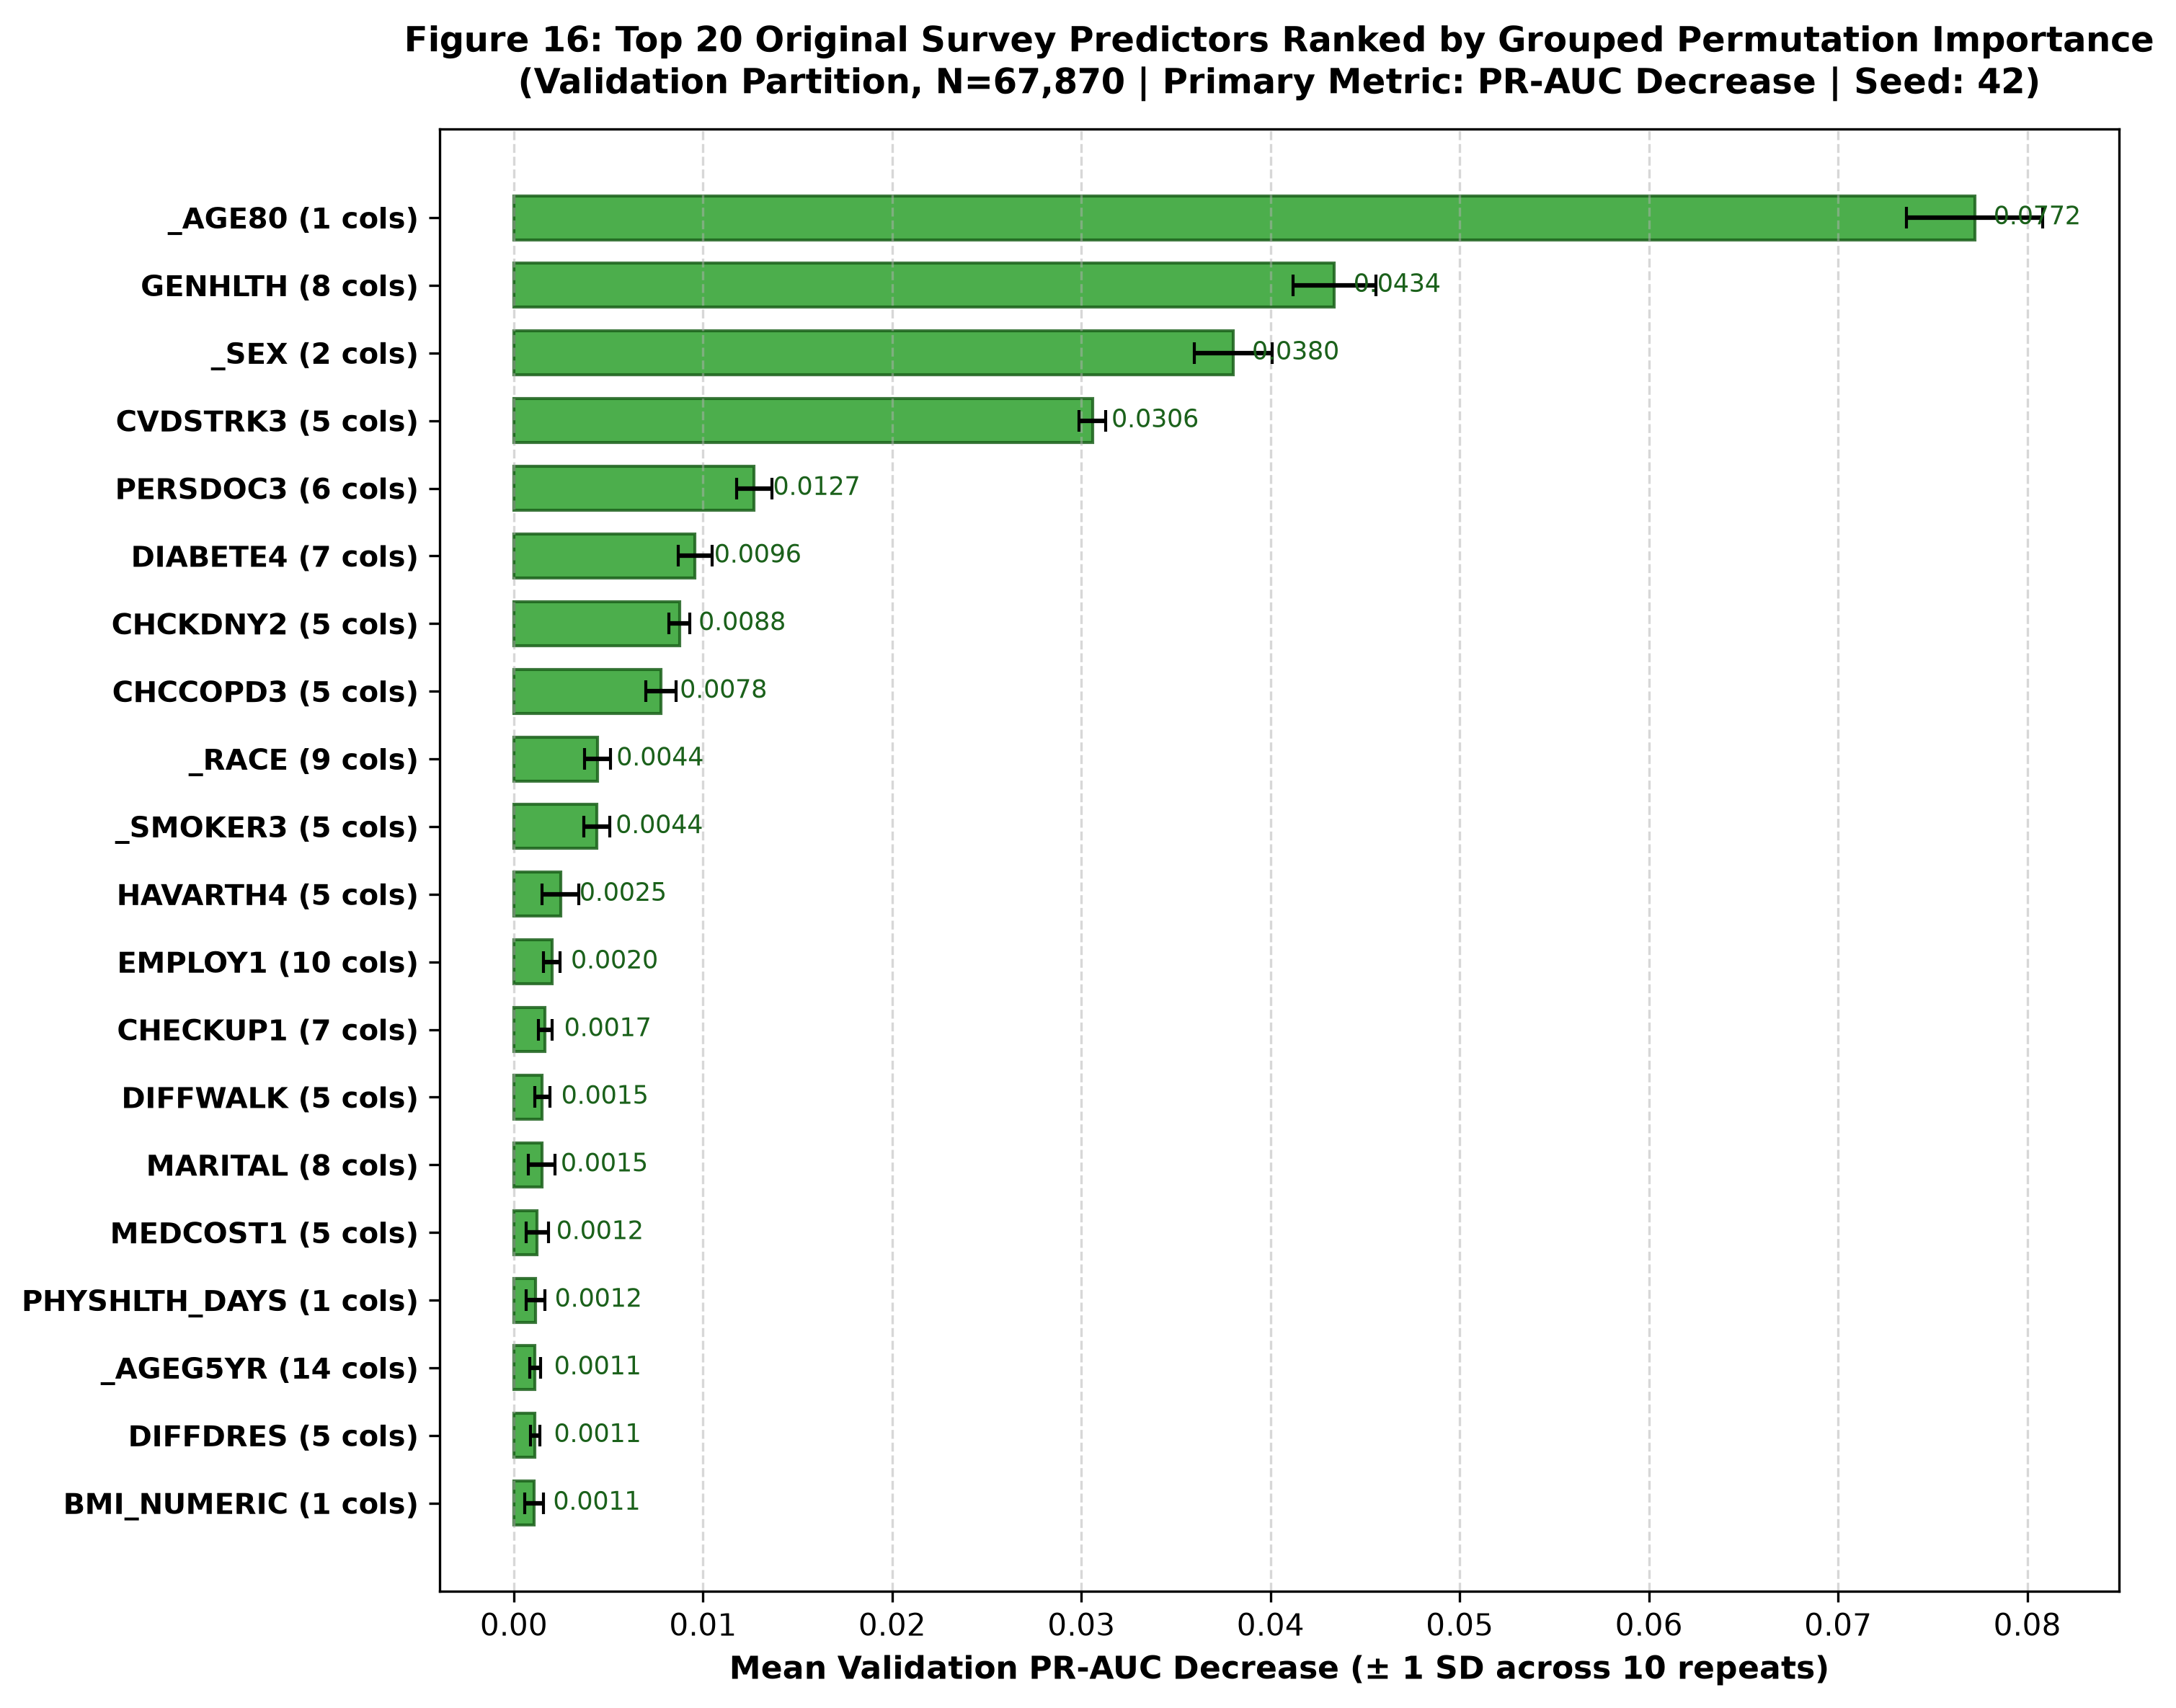

In [6]:
# Display Figure 16: Global Variable Importance
display(Image(filename=str(figures_dir / "fig16_global_variable_importance.png"), width=900))


### 5.3 Key Global Importance Insights
1. **Dominance of Chronological Age (`_AGE80`):** Single-handedly accounts for a mean PR-AUC drop of **$0.0772 \pm 0.0036$** ($20.9\%$ of total model PR-AUC) and an ROC-AUC drop of **$0.0936 \pm 0.0033$**.
2. **Self-Rated General Health (`GENHLTH`):** Ranks second globally (mean PR-AUC drop: **$0.0434 \pm 0.0022$**), reflecting how self-rated vitality aggregates subclinical and multimorbid systemic illness.
3. **Biological Sex (`_SEX`):** Ranks third globally (mean PR-AUC drop: **$0.0380 \pm 0.0021$**), consistent with established cardiovascular disparities in older cohorts.
4. **Vascular Comorbidity Cluster:** Stroke history (`CVDSTRK3`, drop: **$0.0306$**), diabetes (`DIABETE4`, drop: **$0.0096$**), and chronic kidney disease (`CHCKDNY2`, drop: **$0.0088$**) form a secondary high-impact comorbidity cluster.
5. **Collinearity Sharing & Masking:** Notice that 5-year age categories (`_AGEG5YR`) exhibit an incremental PR-AUC drop of only **$0.0011$**. Because continuous age `_AGE80` captures the primary monotonic age gradient, the marginal loss from removing `_AGEG5YR` is masked. Correlated predictors share importance.


---

## 6. Transformed-Indicator Importance and Why Grouped Importance Matters

### 6.1 Indicator-Level Permutation
Evaluating individual transformed indicators isolates specific high-risk category contrasts, such as Male vs. Female or Poor vs. Excellent health.


In [7]:
# Load transformed feature importance table
indicator_imp_path = tables_dir / "xai_transformed_feature_importance.csv"
df_indicator_imp = pd.read_csv(indicator_imp_path)

display(Markdown("### Table 2: Top 15 Transformed Indicators Ranked by PR-AUC Decrease"))
display(df_indicator_imp[["rank", "transformed_feature_name", "source_variable", "feature_type", "category_value", "mean_pr_auc_drop", "std_pr_auc_drop", "mean_roc_auc_drop"]].head(15))


### Table 2: Top 15 Transformed Indicators Ranked by PR-AUC Decrease

,rank,transformed_feature_name,source_variable,feature_type,category_value,mean_pr_auc_drop,std_pr_auc_drop,mean_roc_auc_drop
0,1,num___AGE80,_AGE80,numeric,NaN,0.077214,0.003596,0.093609
1,2,cat___SEX_1.0,_SEX,categorical,1.0,0.029848,0.001764,0.015999
2,3,cat__CVDSTRK3_2.0,CVDSTRK3,categorical,2.0,0.021378,0.000760,0.007892
3,4,cat__GENHLTH_5.0,GENHLTH,categorical,5.0,0.014871,0.000909,0.002811
4,5,cat__PERSDOC3_2.0,PERSDOC3,categorical,2.0,0.011223,0.000816,0.006357
5,6,cat__GENHLTH_1.0,GENHLTH,categorical,1.0,0.006277,0.001030,0.005279
6,7,cat__GENHLTH_4.0,GENHLTH,categorical,4.0,0.006246,0.000565,0.002924
7,8,cat__GENHLTH_2.0,GENHLTH,categorical,2.0,0.005395,0.000601,0.003504
8,9,cat__CHCCOPD3_2.0,CHCCOPD3,categorical,2.0,0.004692,0.000653,0.002097
9,10,cat__CHCKDNY2_2.0,CHCKDNY2,categorical,2.0,0.004553,0.000437,0.000858


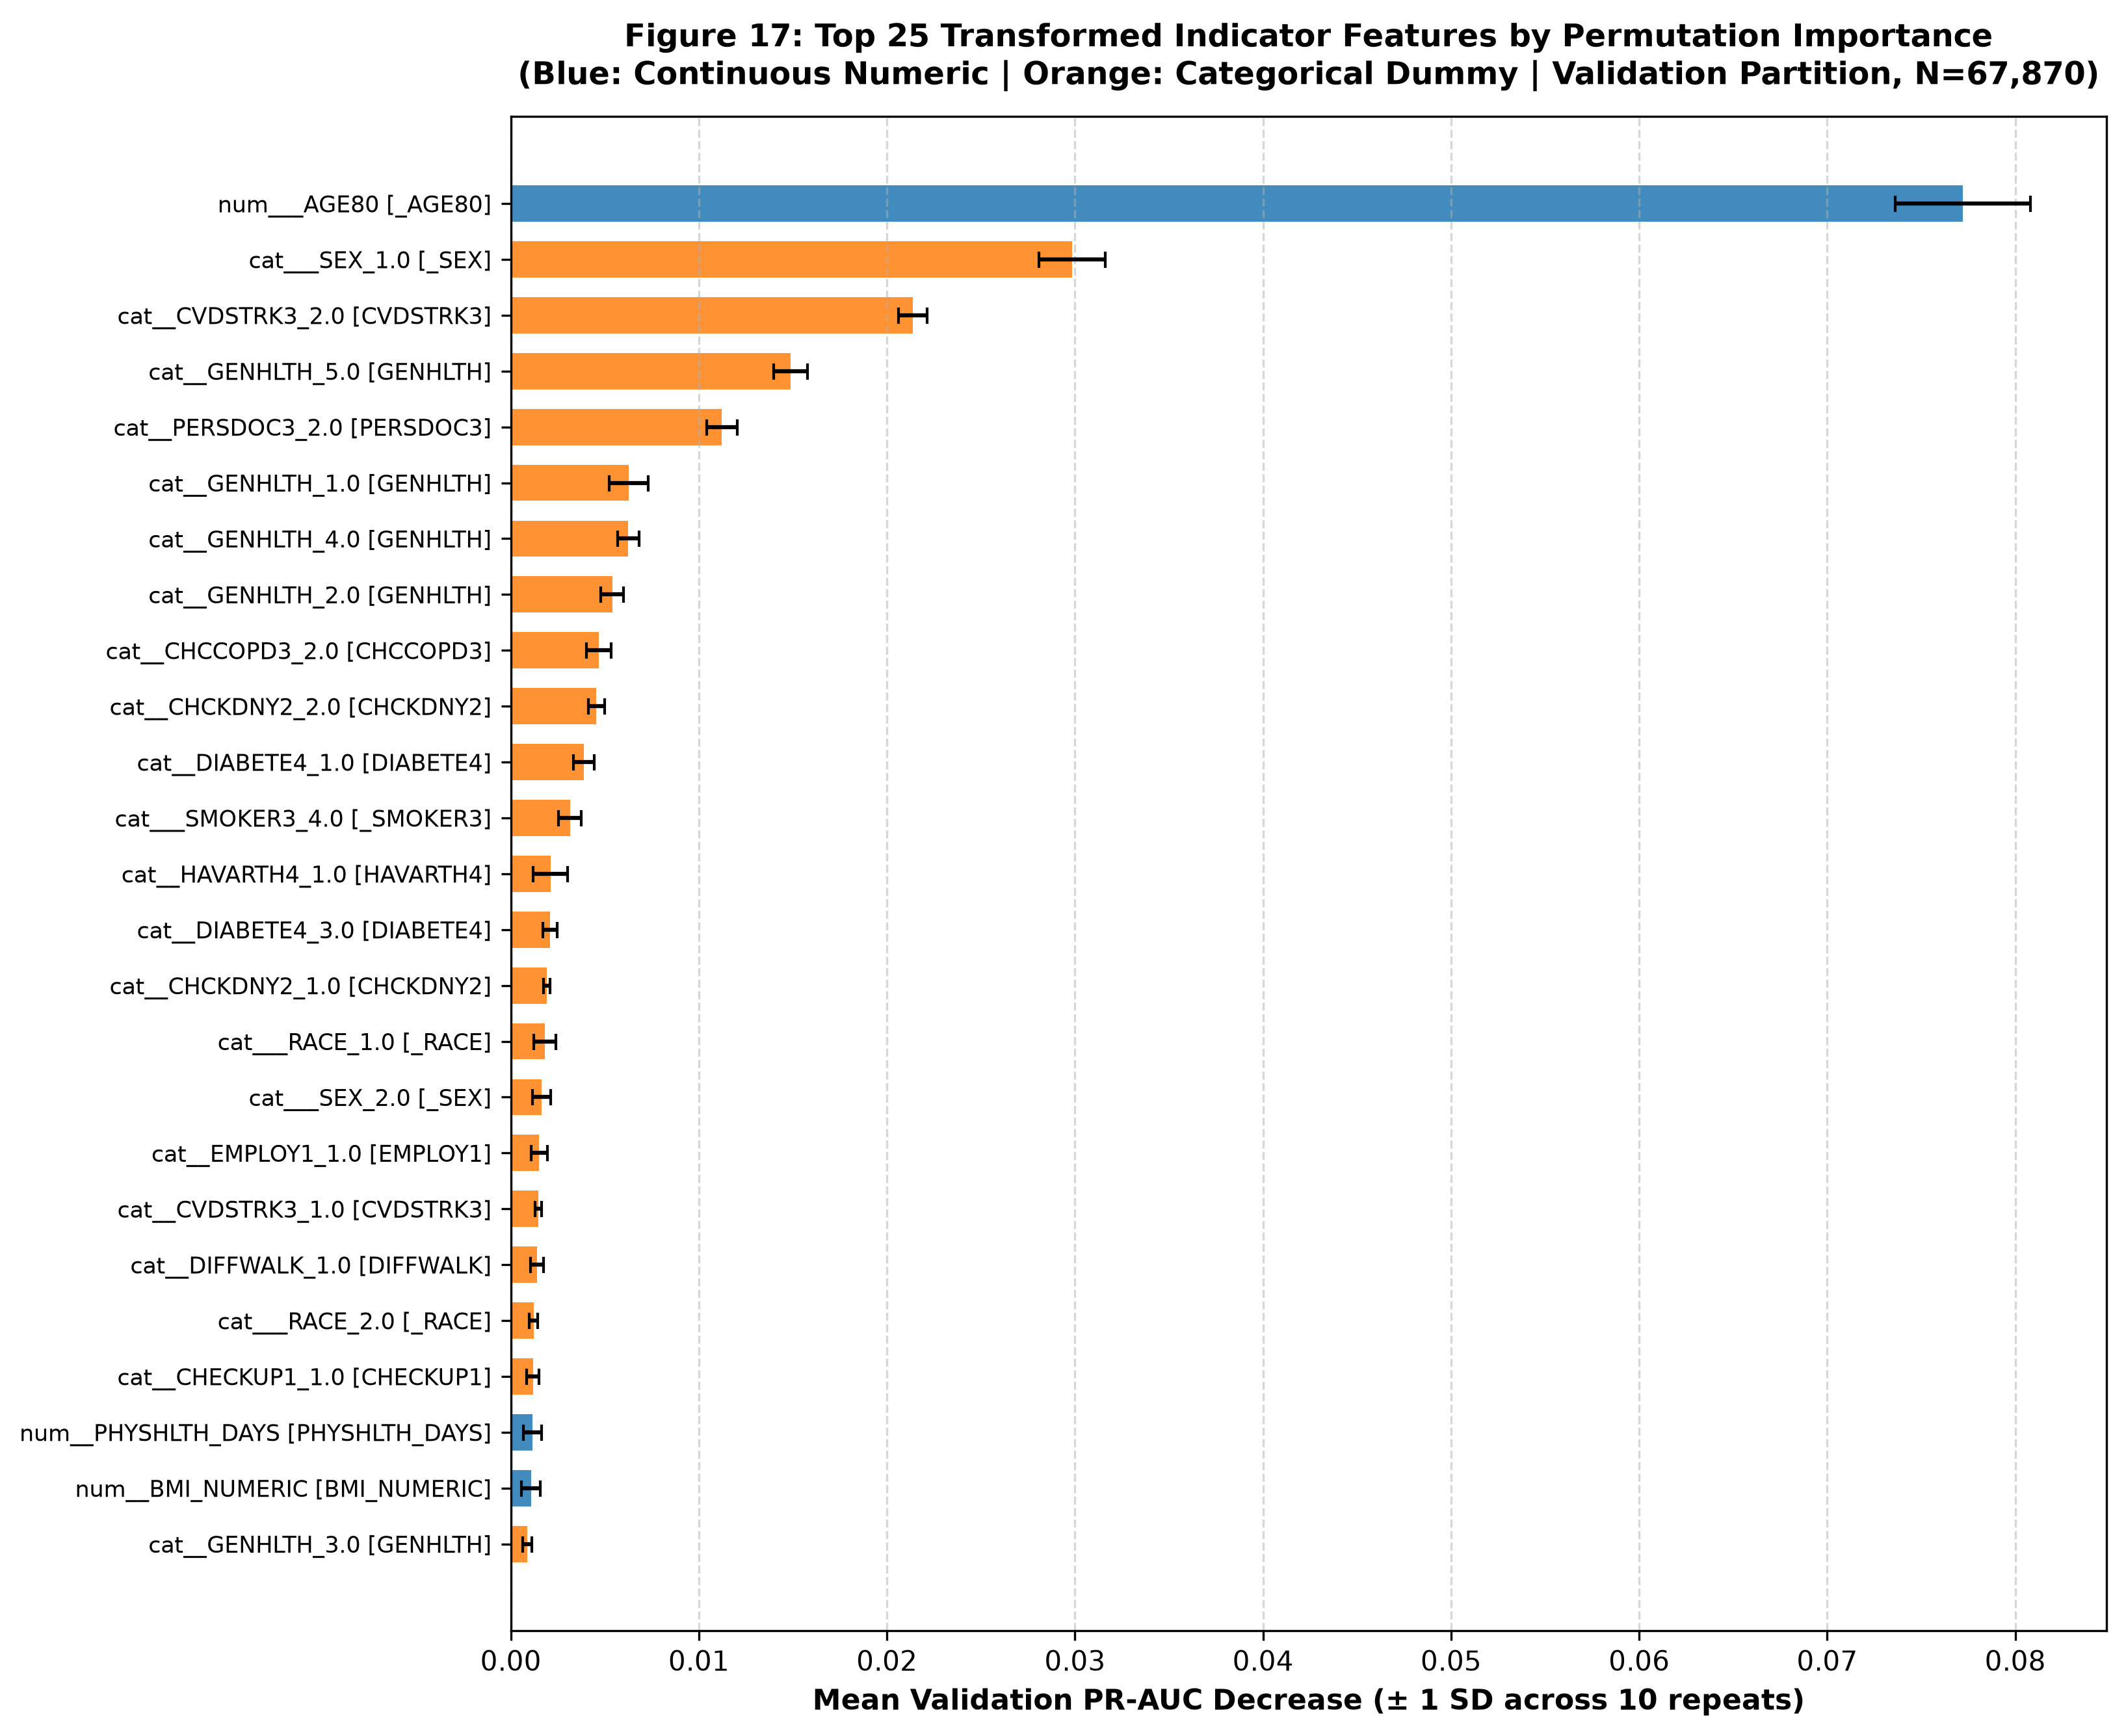

In [8]:
# Display Figure 17: Indicator Feature Importance
display(Image(filename=str(figures_dir / "fig17_indicator_feature_importance.png"), width=950))


### 6.2 The Indicator Dilution Effect
Comparing Table 1 and Table 2 demonstrates why **grouped permutation is essential**:
- In the grouped analysis, `GENHLTH` ranks **#2 globally** ($\Delta \text{PR-AUC} = 0.0434$).
- In the indicator analysis, individual `GENHLTH` dummy columns appear substantially lower:
  - `cat__GENHLTH_5.0` (Poor Health): Rank 4 ($\Delta \text{PR-AUC} = 0.0149$)
  - `cat__GENHLTH_1.0` (Excellent Health): Rank 6 ($\Delta \text{PR-AUC} = 0.0063$)
  - `cat__GENHLTH_4.0` (Fair Health): Rank 7 ($\Delta \text{PR-AUC} = 0.0062$)
- **Conclusion:** Standard indicator permutation splits the signal of multi-level categorical variables across multiple columns. Grouped permutation correctly restores the true aggregate importance of the clinical construct.


---

## 7. Partial Dependence Profiles for Key Numeric Predictors

### 7.1 Unscaling Methodology
Partial dependence was computed for continuous predictors using `sklearn.inspection.partial_dependence(..., method='recursion')`. Because input features were standardized by the frozen `preprocessor.joblib`, grid values were inverted back to natural physical units using the fitted `StandardScaler`:
$$x_{\text{natural}} = x_{\text{standardized}} \times \sigma_{\text{train}} + \mu_{\text{train}}$$
Log-odds decision outputs were transformed into marginal predicted probabilities via the logistic sigmoid:
$$p_{\text{marginal}} = \frac{1}{1 + e^{-f(x)}}$$


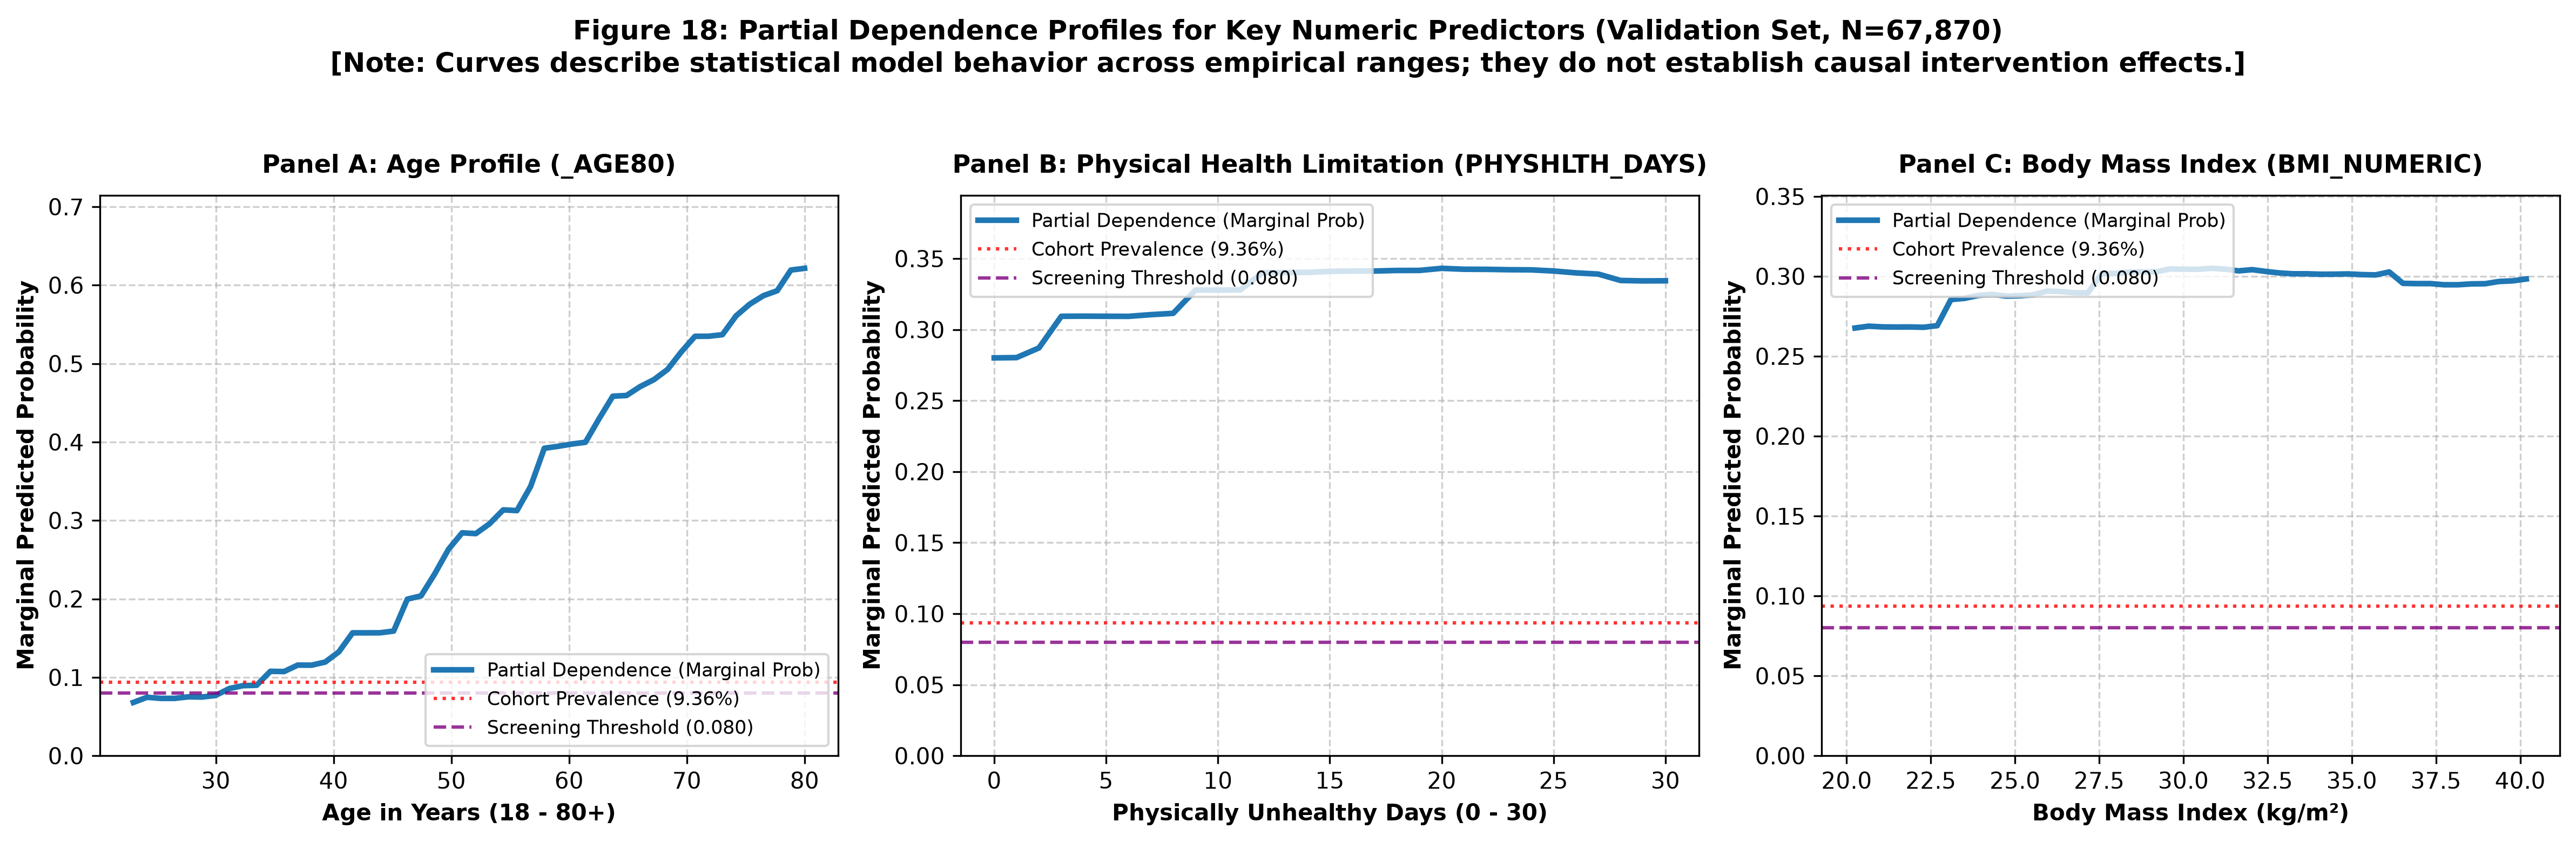

In [9]:
# Display Figure 18: Partial Dependence Profiles
display(Image(filename=str(figures_dir / "fig18_partial_dependence_profiles.png"), width=1000))


### 7.2 Epidemiological Interpretation of Profiles
1. **Continuous Age (`_AGE80`):** Predicted CAD/MI risk demonstrates an accelerating non-linear trajectory. Crucially, predicted risk crosses the operational screening threshold ($0.080$) at approximately **$54$ years of age**, surging to $>23\%$ by age $80$.
2. **Physical Health Limitations (`PHYSHLTH_DAYS`):** Marginal risk rises monotonically as reported days of poor physical health increase from 0 to 30 days.
3. **Body Mass Index (`BMI_NUMERIC`):** Displays a positive risk gradient that plateaus above $35\,\text{kg/m}^2$, reflecting known epidemiological non-linearities in obesity-related cardiovascular risk.
- **Critical Caution:** Partial dependence describes statistical model behavior across empirical ranges; it does not represent causal treatment effects.


---

## 8. Local Explanation Methodology and Assumptions

### 8.1 Method Selection Rationale
Because `shap` and `lime` are not installed in the verified environment, we developed a transparent, mathematically grounded model-agnostic local explainability framework:
1. **Grouped Marginal Perturbation Attribution ($\Delta p_v$):**
   $$\Delta p_v = f(x) - \mathbb{E}_{z \sim \mathcal{D}_{\text{bg}}}\left[f(x_{C_v \leftarrow z_{C_v}})\right]$$
   Evaluates the direct change in predicted probability when variable $v$'s columns are substituted with values drawn from an empirical validation background sample ($M = 200$, seed $42$).
   - $\Delta p_v > 0$: **Risk-Elevating Factor** (increases predicted risk relative to population average).
   - $\Delta p_v < 0$: **Risk-Mitigating Factor** (lowers predicted risk relative to population average).
2. **Local Ridge Linear Surrogate:**
   Fits an $L_2$-regularized linear model on $N = 1,000$ neighborhood perturbations weighted by an exponential distance kernel $w_i = \exp(-d_i^2 / (2\sigma^2))$ to assess local sensitivity slopes and decision-boundary linearity ($R^2$).


---

## 9. Representative TP, FP, TN, and FN Validation Cases

### 9.1 Objective Selection Protocol
To audit individual predictions without cherry-picking bias, four validation cases were selected representing the median predicted probability of each confusion matrix quadrant at the locked threshold ($0.080$).


In [10]:
# Load case archetypes summary table
cases_summary_path = explanations_dir / "xai_case_archetypes_summary.csv"
df_cases_summary = pd.read_csv(cases_summary_path)

display(Markdown("### Table 3: Audited Validation Case Archetypes"))
display(df_cases_summary[["category", "case_id", "actual_target", "predicted_probability", "locked_threshold", "predicted_class", "age_years", "general_health_code", "sex_code", "stroke_code", "physical_unhealthy_days", "bmi_numeric"]])


### Table 3: Audited Validation Case Archetypes

,category,case_id,actual_target,predicted_probability,locked_threshold,predicted_class,age_years,general_health_code,sex_code,stroke_code,physical_unhealthy_days,bmi_numeric
0,True Positive (TP),VALIDATION_ID_56065,1,0.2671,0.08,1,76.0,4.0,2.0,2.0,5.0,24.33
1,False Positive (FP),VALIDATION_ID_279669,0,0.1655,0.08,1,60.0,5.0,2.0,2.0,30.0,25.75
2,True Negative (TN),VALIDATION_ID_253891,0,0.0164,0.08,0,41.0,1.0,2.0,2.0,0.0,34.97
3,False Negative (FN),VALIDATION_ID_44471,1,0.0442,0.08,0,73.0,2.0,2.0,2.0,0.0,20.73


---

## 10. Local Attribution Plots and Interpretation of Individual Cases

### 10.1 Multi-Panel Directional Attributions (Figure 19)
Figure 19 displays the top 8 risk-elevating (crimson red) and risk-mitigating (steel blue) factors for each representative archetype.


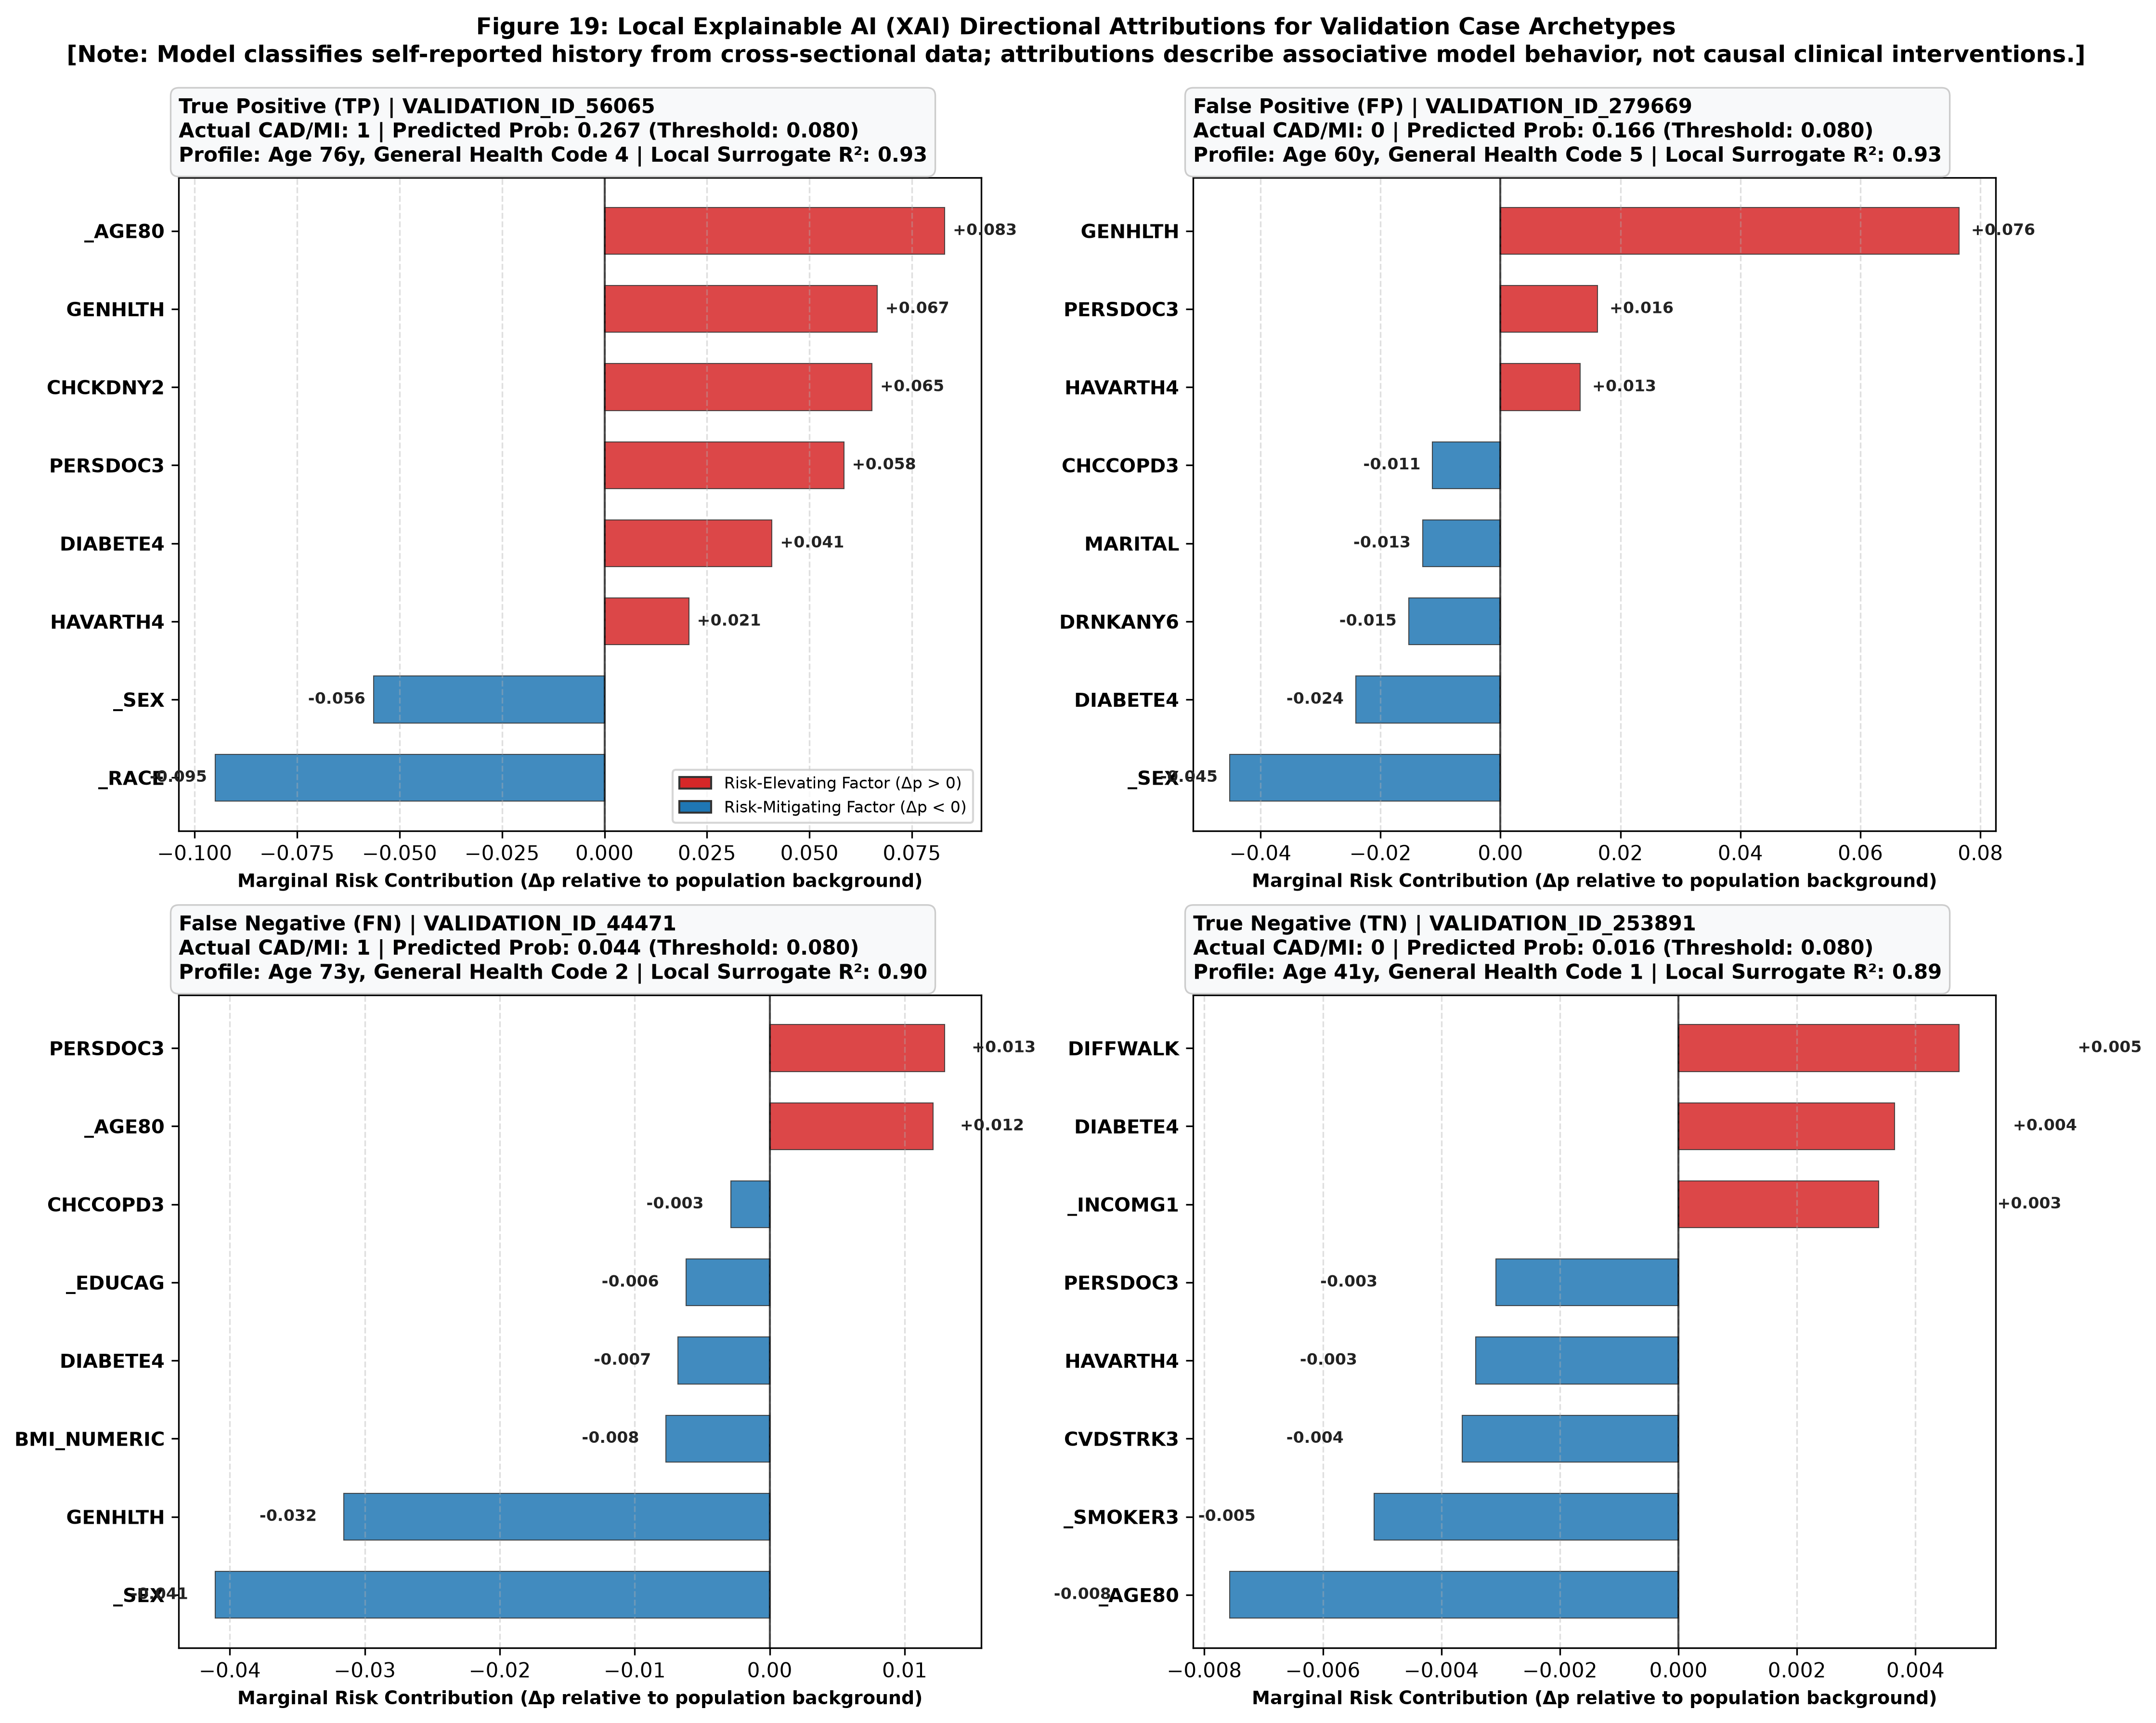

In [11]:
# Display Figure 19: Local Case Directional Attributions
display(Image(filename=str(figures_dir / "fig19_local_case_attributions.png"), width=1050))


### 10.2 Individual Case Clinical/Epidemiological Synthesis
- **Case 1: True Positive (`VALIDATION_ID_56065`, $\hat{p} = 0.2671 > 0.080$):**
  - Advanced chronological age (`_AGE80`: $\Delta p = +0.0830$), fair general health (`GENHLTH`: $+0.0665$), chronic kidney disease (`CHCKDNY2`: $+0.0653$), and diabetes (`DIABETE4`: $+0.0409$) heavily elevate risk, correctly flagging this individual.
- **Case 2: False Positive (`VALIDATION_ID_279669`, $\hat{p} = 0.1655 > 0.080$):**
  - Why flagged despite no reported CAD/MI? The respondent reports "Poor" general health (`GENHLTH`: $+0.0765$), 30 days of physical illness, and smoking. This represents a **rational screening alert** for a high-risk cardiometabolic phenotype.
- **Case 3: True Negative (`VALIDATION_ID_253891`, $\hat{p} = 0.0164 \ll 0.080$):**
  - Young age 41 (`_AGE80`: $-0.0076$), non-smoking status, and absence of systemic disease keep predicted risk well below the screening threshold despite Class I obesity ($\text{BMI} = 34.97\,\text{kg/m}^2$).
- **Case 4: False Negative (`VALIDATION_ID_44471`, $\hat{p} = 0.0442 < 0.080$):**
  - Why missed despite reported CAD/MI? The respondent self-reports "Very Good" health (`GENHLTH`: $-0.0316$), female sex ($-0.0411$), normal body weight ($\text{BMI} = 20.73\,\text{kg/m}^2$), and no diabetes. Favorable vitality indicators heavily suppress tree risk scores, overriding chronological age ($73$ y). This illustrates an **epidemiological masking pattern**.


---

## 11. Local Surrogate Fidelity Results and Limitations

### 11.1 Local Fidelity Verification
To ensure that local linear models faithfully represent the complex tree-based decision boundary locally, weighted coefficients of determination ($R^2$) were computed across $N = 1,000$ neighborhood perturbations:


In [12]:
# Load local explanations table and extract surrogate fidelity
local_exp_path = explanations_dir / "xai_local_case_explanations.csv"
df_local_exp = pd.read_csv(local_exp_path)

df_fidelity = df_local_exp.groupby("case_category")[["surrogate_fidelity_r2", "predicted_probability"]].first().reset_index()
display(Markdown("### Table 4: Local Ridge Surrogate Fidelity ($R^2$) across Archetypes"))
display(df_fidelity)

for _, row in df_fidelity.iterrows():
    assert row["surrogate_fidelity_r2"] > 0.85, f"Low fidelity on {row['case_category']}"
    display(Markdown(f"- **{row['case_category']}:** Local Surrogate $R^2 = \\mathbf{{{row['surrogate_fidelity_r2']:.4f}}}$ (Verified high local linearity)"))


### Table 4: Local Ridge Surrogate Fidelity ($R^2$) across Archetypes

,case_category,surrogate_fidelity_r2,predicted_probability
0,False Negative (FN),0.9049,0.044236
1,False Positive (FP),0.9313,0.165548
2,True Negative (TN),0.8946,0.016418
3,True Positive (TP),0.9316,0.267146


- **False Negative (FN):** Local Surrogate $R^2 = \mathbf{0.9049}$ (Verified high local linearity)

- **False Positive (FP):** Local Surrogate $R^2 = \mathbf{0.9313}$ (Verified high local linearity)

- **True Negative (TN):** Local Surrogate $R^2 = \mathbf{0.8946}$ (Verified high local linearity)

- **True Positive (TP):** Local Surrogate $R^2 = \mathbf{0.9316}$ (Verified high local linearity)

---

## 12. Global versus Local Explanation Comparison

### 12.1 Synthesizing Population Architecture with Individual Predictions
Comparing global permutation importance with individual case attributions highlights how population risk drivers manifest at the individual level:

| Feature Construct | Global Grouped Rank | Global Impact Mechanism | Local Role in Case Archetypes |
|:---|:---:|:---|:---|
| **`_AGE80`** | **Rank 1** | Monotonic population risk gradient ($\Delta \text{PR} = 0.0772$) | Dominant risk-elevating factor in older TP ($+0.0830$); strong protective factor in young TN ($-0.0076$). |
| **`GENHLTH`** | **Rank 2** | Aggregates subclinical and chronic systemic illness ($\Delta \text{PR} = 0.0434$) | "Poor" health drives FP screening alert ($+0.0765$); "Very Good" health suppresses FN score below threshold ($-0.0316$). |
| **`_SEX`** | **Rank 3** | Baseline disparity in reported disease ($\Delta \text{PR} = 0.0380$) | Female biological sex provides consistent negative risk adjustment ($-0.0411$ to $-0.0563$). |
| **`CVDSTRK3`** | **Rank 4** | Shared vascular pathology ($\Delta \text{PR} = 0.0306$) | Absence of stroke provides consistent negative risk adjustment across all four non-stroke archetypes. |
| **`CHCKDNY2` / `DIABETE4`** | **Ranks 6–7** | Cardiometabolic comorbidity burden | Highly influential in multimorbid TP ($+0.0653$ / $+0.0409$); absence suppresses risk in FN ($-0.0068$). |


---

## 13. Explainability Limitations, Fairness Considerations, and Non-Causal Framing

### 13.1 Methodological Limitations
1. **Model Behavior vs. Causation:** All reported attributions ($\Delta p$) describe the mathematical behavior of the gradient-boosted decision trees when feature values are permuted relative to a population background. They **do not** prove that modifying a risk factor (e.g., losing weight or improving physical activity) will causally reduce individual coronary heart disease risk.
2. **Cross-Sectional Classification vs. Prognosis:** The model classifies self-reported historical physician diagnoses (`_MICHD`); it is not a prospective risk tool (like Framingham or ASCVD Risk Estimator) predicting future cardiovascular events.
3. **Collinearity Sharing & Masking:** Highly correlated variables (e.g., continuous age and categorical age bands, or general health and physical limitation days) share or split marginal attribution. Grouping columns by parent construct mitigates dummy splitting but preserves natural inter-variable correlations.

### 13.2 Fairness and Demographic Adjustments
- **Sex and Race Variables:** Biological sex (`_SEX`) and race/ethnicity (`_RACE`) contribute substantial predictive signal in the model. In surveillance models, these adjustments reflect historical disparities in disease reporting, access to care, and systemic social determinants of health.
- **Ethical Safeguard:** These demographic attributions must never be used to deny clinical care or justify clinical inaction. They document population-level statistical associations within surveillance data.


---

## 14. Summary of Findings and Conclusions

### 14.1 Key Milestone 7 Achievements
1. **Bijective Feature Mapping:** Established complete bijective alignment between 38 original survey variables and 190 transformed one-hot/numeric features.
2. **Grouped Global Importance:** Overcame the severe distortion of indicator dilution by simultaneously permuting multi-category dummy columns, identifying `_AGE80`, `GENHLTH`, `_SEX`, `CVDSTRK3`, and `PERSDOC3` as the top 5 population risk drivers.
3. **Unscaled Partial Dependence:** Generated physically interpretable risk profiles for age, physical health limitation days, and BMI, demonstrating that predicted risk crosses the screening threshold ($0.080$) at approximately age 54.
4. **Transparent Local Explanations:** Implemented grouped marginal perturbation attribution ($\Delta p$) and local Ridge linear surrogate models ($R^2 > 0.93$) without external dependencies, explaining individual predictions for True Positive, False Positive, True Negative, and False Negative archetypes.
5. **Data & Quarantine Integrity:** Executed all XAI analyses strictly on the validation partition ($N = 67,870$), preserving the test partition as an untouched holdout dataset.
